In [ ]:
!pip install transformers datasets librosa torchaudio accelerate matplotlib captum

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 17.7 MB/s eta 0:00:00


In [ ]:
import torch
import numpy as np
from transformers import TrainingArguments, Trainer
import matplotlib.pyplot as plt
import seaborn as sns

###Φόρτωση συνόλου


In [ ]:
from datasets import load_dataset, Audio

#Φόρτωση του dataset, από το HuggingFace
dataset = load_dataset("AbstractTTS/CREMA-D", split="train")

#Μετατροπή συχνότητας σε 16kHz
dataset = dataset.cast_column("audio", Audio(sampling_rate=16_000))

print(dataset.features)
print(dataset[0]["file"], dataset[0]["major_emotion"])

README.md:   0%|          | 0.00/847 [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  308MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  298MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/7442 [00:00<?, ? examples/s]

{'file': Value('string'), 'audio': Audio(sampling_rate=16000, decode=True, num_channels=None, stream_index=None), 'angry': Value('float32'), 'sad': Value('float32'), 'disgust': Value('float32'), 'fear': Value('float32'), 'neutral': Value('float32'), 'happy': Value('float32'), 'gender': Value('string'), 'transcription': Value('string'), 'major_emotion': Value('string'), 'speaking_rate': Value('float32'), 'pitch_mean': Value('float32'), 'pitch_std': Value('float32'), 'rms': Value('float32'), 'relative_db': Value('float32')}
1001_DFA_ANG_XX.wav anger


In [ ]:
labels = sorted(set(dataset["major_emotion"]))   # ['anger','disgust','fear','happy','neutral','sad']
num_labels = len(labels)
label2id = {name: i for i, name in enumerate(labels)}
id2label = {i: name for i, name in enumerate(labels)}

def add_speaker(batch):
    batch["actor_id"] = batch["file"].split("_")[0]   # π.χ. "1001_DFA_ANG_XX.wav" -> "1001"
    return batch

dataset = dataset.map(add_speaker)
print(len(set(dataset["actor_id"])), "μοναδικοί ομιλητές")

Map:   0%|          | 0/7442 [00:00<?, ? examples/s]

91 μοναδικοί ομιλητές


In [ ]:
from sklearn.model_selection import GroupShuffleSplit

actor_ids = dataset["actor_id"]
splitter = GroupShuffleSplit(test_size=0.2, n_splits=1, random_state=42)
train_idx, test_idx = next(splitter.split(X=range(len(dataset)), groups=actor_ids))

from datasets import DatasetDict
dataset = DatasetDict({
    "train": dataset.select(train_idx),
    "test": dataset.select(test_idx)
})

# Έλεγχος ότι δεν υπάρχει επικάλυψη ομιλητών
train_speakers = set(dataset["train"]["actor_id"])
test_speakers = set(dataset["test"]["actor_id"])
print("Επικάλυψη:", train_speakers & test_speakers)  # πρέπει να είναι κενό σύνολο

Επικάλυψη: set()


###Φόρτωση μοντέλου και προετοιμασία συνόλου

In [ ]:
from transformers import AutoFeatureExtractor, AutoModelForAudioClassification
import torch

checkpoint = "facebook/data2vec-audio-base-960h"
feature_extractor = AutoFeatureExtractor.from_pretrained(checkpoint)

model = AutoModelForAudioClassification.from_pretrained(
    checkpoint,
    num_labels=num_labels,
    label2id=label2id,
    id2label=id2label,
    ignore_mismatched_sizes=True
)

model.freeze_feature_encoder()

if torch.cuda.is_available():
    model = model.to("cuda")

preprocessor_config.json:   0%|          | 0.00/256 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.64k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  373MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/230 [00:00<?, ?it/s]

[transformers] Data2VecAudioForSequenceClassification LOAD REPORT from: facebook/data2vec-audio-base-960h
Key               | Status     | 
------------------+------------+-
lm_head.bias      | UNEXPECTED | 
lm_head.weight    | UNEXPECTED | 
projector.weight  | MISSING    | 
classifier.bias   | MISSING    | 
classifier.weight | MISSING    | 
projector.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
MAX_LENGTH = 6 * 16000  # 6 δευτερόλεπτα στα 16kHz

def prepare_dataset(batch):
    audio = batch["audio"]
    batch["input_values"] = feature_extractor(
        audio["array"],
        sampling_rate=audio["sampling_rate"],
        max_length=MAX_LENGTH,
        truncation=True
    ).input_values[0]
    batch["labels"] = label2id[batch["major_emotion"]]
    return batch

encoded_dataset = dataset.map(prepare_dataset, remove_columns=dataset["train"].column_names)

Map:   0%|          | 0/5890 [00:00<?, ? examples/s]

Map:   0%|          | 0/1552 [00:00<?, ? examples/s]

### Ορισμός μετρικών αξιολόγησης

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,

    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    cohen_kappa_score,
    roc_auc_score,
    log_loss,
    confusion_matrix,

    roc_auc_score,
    average_precision_score
)

from sklearn.preprocessing import label_binarize
from scipy.special import softmax

In [ ]:
import numpy as np

#Λίστα για την αποθήκευση των confusion matrices
all_confusion_matrices = []

#Συνάρτηση υπολογισμού των μετρικών αξιολόγησης
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    probs = softmax(logits, axis=1)

    num_classes = probs.shape[1]
    labels_bin = label_binarize(labels, classes=list(range(num_classes)))

    # ROC-AUC (macro-averaged, one-vs-rest)
    roc_auc = roc_auc_score(
        labels_bin, probs, multi_class="ovr", average="macro"
    )

    # PR-AUC (macro-averaged average precision)
    pr_auc = average_precision_score(
        labels_bin, probs, average="macro"
    )

    accuracy = accuracy_score(labels, predictions)
    balanced_accuracy = balanced_accuracy_score(labels, predictions)
    precision = precision_score(labels, predictions, average="weighted")
    recall = recall_score(labels, predictions, average="weighted")
    f1 = f1_score(labels, predictions, average="weighted")
    mcc = matthews_corrcoef(labels, predictions)
    k_score = cohen_kappa_score(labels, predictions)
    logloss = log_loss(labels, probs)

    cm = confusion_matrix(labels, predictions)
    all_confusion_matrices.append(cm)

    return {
        "accuracy": accuracy,
        "precision": precision,
        "balanced accuracy" : balanced_accuracy,
        "recall": recall,
        "f1": f1,
        "mcc" : mcc,
        "k_score" : k_score,
        "log_loss": logloss,
        "roc_auc": roc_auc,
        "pr_auc": pr_auc
    }

In [ ]:
label2id_fixed = {str(label): i for i, label in enumerate(labels)}
id2label_fixed = {i: str(label) for i, label in enumerate(labels)}

### Ορισμός παραμέτρων εκπαίδευσης

In [ ]:
# Δυναμικός υπολογισμός warmup_steps (10% των συνολικών training steps)
per_device_train_batch_size = 8
gradient_accumulation_steps = 4
num_train_epochs = 10

effective_batch_size = per_device_train_batch_size * gradient_accumulation_steps
steps_per_epoch = len(encoded_dataset["train"]) // effective_batch_size
total_steps = steps_per_epoch * num_train_epochs
warmup_steps = max(1, int(0.1 * total_steps))

#Καθορισμός μετρικών εκπαίδευσης του μοντέλου
training_args = TrainingArguments(
    output_dir="./data2vec-finetuned-CREMA-D",
    per_device_train_batch_size=per_device_train_batch_size,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=gradient_accumulation_steps,
    eval_strategy="epoch",
    save_strategy="epoch",
    num_train_epochs=num_train_epochs,
    fp16=True,
    logging_steps=50,
    learning_rate=3e-5,
    warmup_steps=warmup_steps,
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    push_to_hub=False,
)

#Δημιουργία DataCollator για padding των δεδομένων
class DataCollatorCTCWithPadding:
    def __init__(self, feature_extractor, padding=True):
        self.feature_extractor = feature_extractor
        self.padding = padding

    def __call__(self, features):
        input_features = [{"input_values": feature["input_values"]} for feature in features]
        batch = self.feature_extractor.pad(
            input_features,
            padding=self.padding,
            return_tensors="pt",
        )

        batch["labels"] = torch.tensor([feature["labels"] for feature in features], dtype=torch.long)
        return batch

data_collator = DataCollatorCTCWithPadding(feature_extractor=feature_extractor, padding=True)

### Δημιουργία και Εκπαίδευση του Trainer

In [ ]:
#Κλήση του trainer και εισαγωγή των παραμέτρων εκπαίδευσης
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=encoded_dataset["train"],
    eval_dataset=encoded_dataset["test"],
    compute_metrics=compute_metrics,
    data_collator=data_collator,
)

print("Εκκίνηση εκπαίδευσης...")
trainer.train()
print("Εκπαίδευση ολοκληρώθηκε!")

Εκκίνηση εκπαίδευσης...


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Mcc,K Score,Log Loss,Roc Auc,Pr Auc,Runtime,Samples Per Second,Steps Per Second
1,6.814242,1.576620,0.342784,0.210448,0.342784,0.227065,0.243119,0.209654,1.576618,0.697980,0.309388,46.462400,33.403000,4.175000
2,5.688595,1.345144,0.485825,0.498125,0.485825,0.469284,0.389759,0.382116,1.345132,0.808962,0.492601,47.251700,32.845000,4.106000
3,4.520298,1.228835,0.556701,0.568838,0.556701,0.535503,0.477014,0.468226,1.228813,0.852522,0.581091,46.640300,33.276000,4.159000
4,4.263934,1.082179,0.619201,0.617497,0.619201,0.611836,0.545473,0.543278,1.082190,0.884889,0.651586,46.504900,33.373000,4.172000
5,3.708434,1.204823,0.620490,0.632507,0.620490,0.611763,0.550638,0.544487,1.204820,0.866047,0.632305,46.070500,33.687000,4.211000
6,3.505861,1.028836,0.660438,0.665228,0.660438,0.654986,0.595448,0.592659,1.028848,0.896635,0.702423,46.524700,33.359000,4.170000
7,3.024873,1.101798,0.648196,0.656610,0.648196,0.641646,0.582412,0.578117,1.101803,0.894612,0.703964,47.470500,32.694000,4.087000
8,3.112025,1.077027,0.659794,0.663013,0.659794,0.654433,0.594608,0.591686,1.077034,0.896015,0.703368,47.367100,32.765000,4.096000
9,3.018871,1.055908,0.666237,0.668723,0.666237,0.660992,0.602048,0.599578,1.055905,0.900494,0.713931,45.802100,33.885000,4.236000
10,2.829608,1.038490,0.668170,0.668871,0.668170,0.663343,0.603871,0.601837,1.038488,0.902867,0.714362,46.278900,33.536000,4.192000


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (4 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Εκπαίδευση ολοκληρώθηκε!


In [ ]:
#Εκτύπωση των τελικών αποτελεσμάτων της εκπαίδευσης
eval_results = trainer.evaluate()
print(f"Αποτελέσματα αξιολόγησης: {eval_results}")

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1,Mcc,K Score,Log Loss,Roc Auc,Pr Auc,Runtime,Samples Per Second,Steps Per Second
2.829608,1.038490,10,0.668170,0.668871,0.668170,0.663343,0.603871,0.601837,1.038488,0.902867,0.714362,46.872800,33.111000,4.139000


Αποτελέσματα αξιολόγησης: {'eval_loss': 1.0384904146194458, 'eval_accuracy': 0.6681701030927835, 'eval_precision': 0.6688705112910427, 'eval_recall': 0.6681701030927835, 'eval_f1': 0.6633426099522122, 'eval_mcc': 0.6038710065640144, 'eval_k_score': 0.6018367873556978, 'eval_log_loss': 1.0384877304091462, 'eval_roc_auc': 0.9028674241374764, 'eval_pr_auc': 0.7143618917994411, 'eval_runtime': 46.8728, 'eval_samples_per_second': 33.111, 'eval_steps_per_second': 4.139}


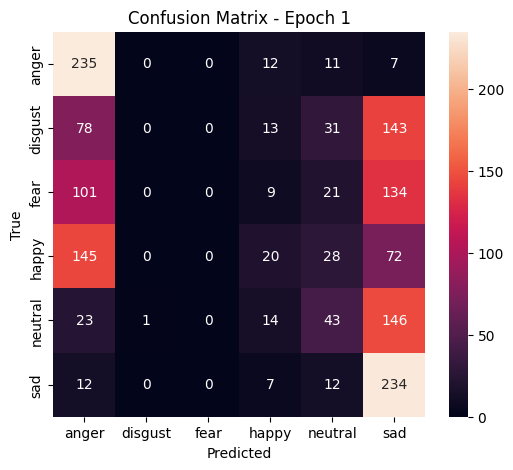

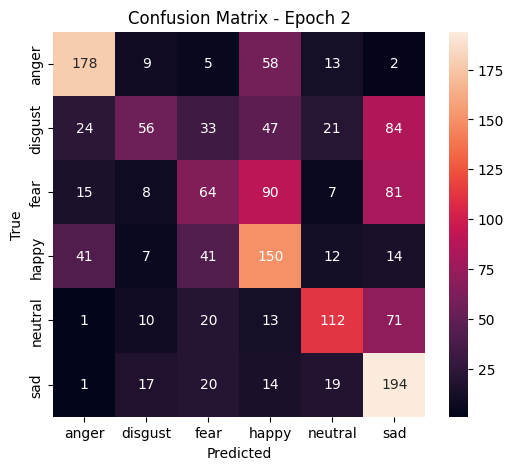

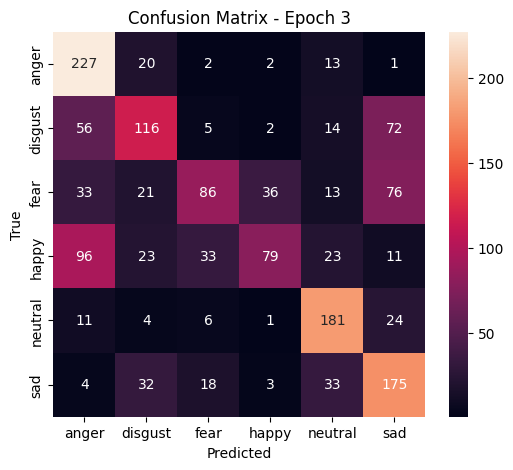

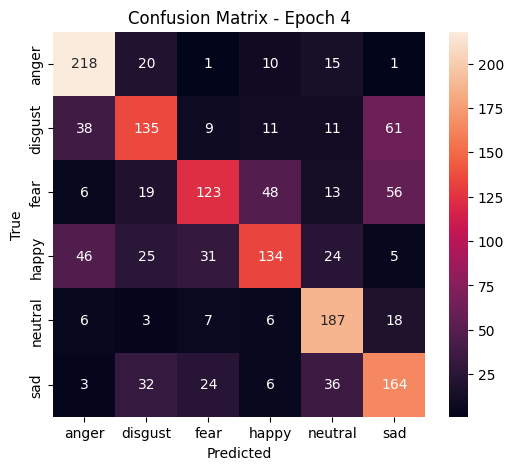

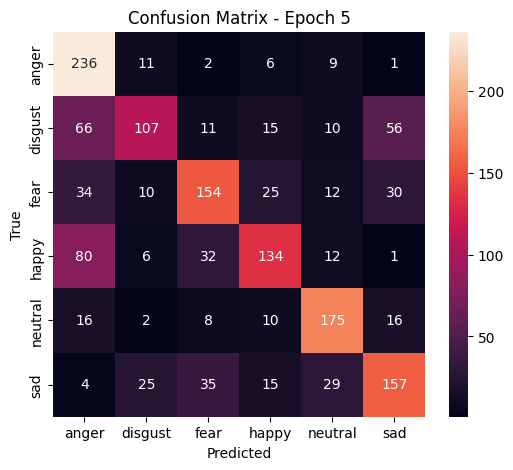

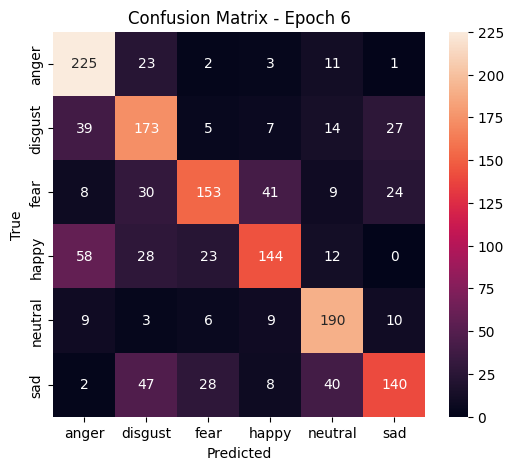

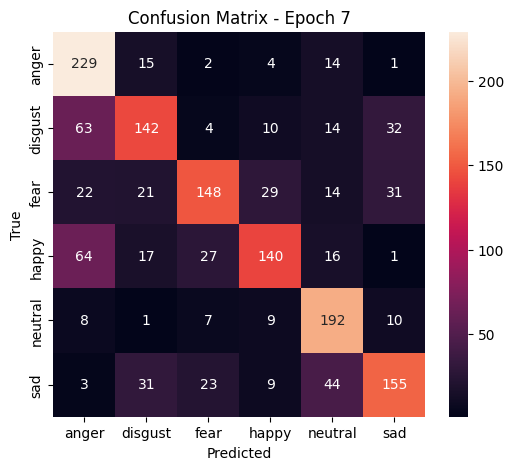

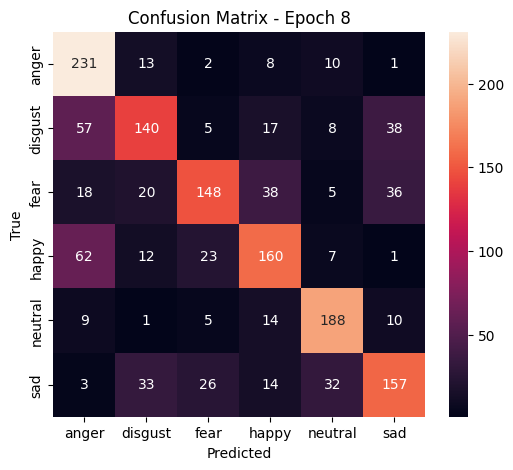

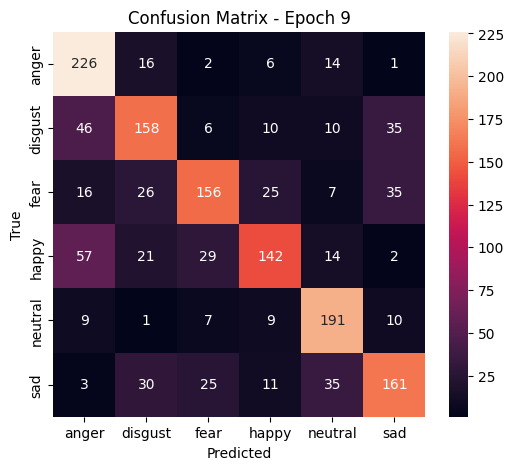

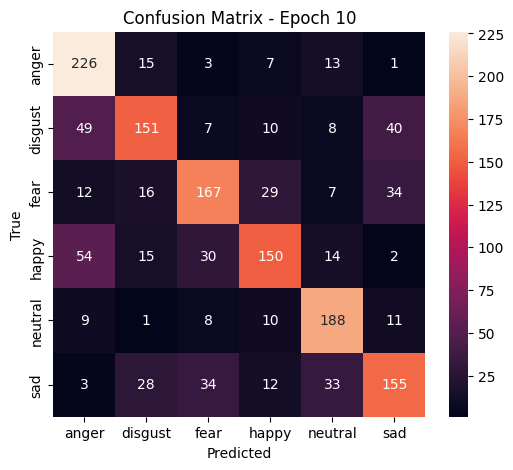

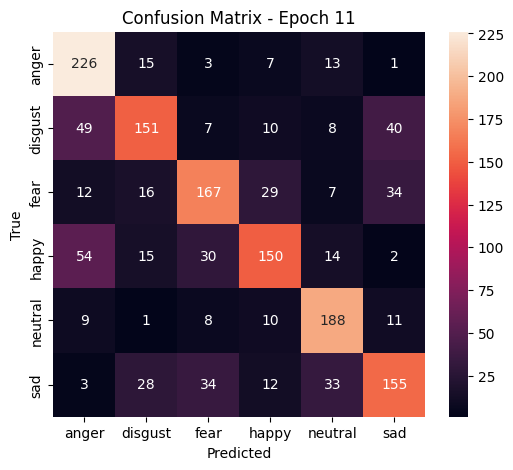

In [ ]:
#Αποθήκευση των ετικετών για τους άξονες των matrices
labels = [
    model.config.id2label[i]
    for i in sorted(model.config.id2label.keys())
]

#Loop στην λίστα με τα confusion matrices
for epoch, cm in enumerate(all_confusion_matrices):
  #Δημιοργία γραφήματος
  plt.figure(figsize=(6,5))

  #Δηνιουργία Heatmap
  sns.heatmap(
      cm,
      annot=True,
      fmt="d",
      xticklabels=labels,
      yticklabels=labels
  )

  plt.title(f"Confusion Matrix - Epoch {epoch+1}")
  plt.xlabel("Predicted")
  plt.ylabel("True")
  plt.show()

Αποθήκευση μοντέλου

In [ ]:
repo_id = "VasilisAsim/data2vec-finetuned-CREMA-D"

#Αποθήκευση του μοντέλου στο HuggingFace
model.push_to_hub(repo_id)

#Αποθήκευση του Feature Extractor
feature_extractor.push_to_hub(repo_id)

print(f"Το μοντέλο και ο επεξεργαστής αποθηκεύτηκαν στο Hugging Face Hub με ID: {repo_id}")

README.md:   0%|          | 0.00/5.17k [00:00<?, ?B/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...cs438j5/model.safetensors:   0%|          |  551kB /  373MB            

No files have been modified since last commit. Skipping to prevent empty commit.


Το μοντέλο και ο επεξεργαστής αποθηκεύτηκαν στο Hugging Face Hub με ID: VasilisAsim/data2vec-finetuned-CREMA-D
